# 03 — Promotion uplift and return

**Questions**
1. Of the units sold during a promotion, how many would have sold anyway (**baseline**) and how many did the promotion add (**incremental**)?
2. How much of the incremental volume comes from the price cut, and how much from feature and display?
3. Does the extra volume pay for the discount given on *every* unit, including the baseline ones?

**Method** — the price models of notebook 02 (main specification) are reused to build a counterfactual for each promoted week: the same store, week, season and competitors, but shelf price back to base price and no feature or display.

- baseline units = actual units × exp(prediction without promotion − prediction as observed)
- units with the price cut only = actual units × exp(prediction without feature/display − prediction as observed)
- incremental = actual − baseline, split into *from price* and *from support*

Applying predicted **ratios** to actual units keeps each week's own noise in both numbers, so the baseline never exceeds what is plausible for that specific week.

Code: `src/promo_pricing/uplift.py`, tested in `tests/test_uplift.py`.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from promo_pricing.elasticity import load_panel
from promo_pricing.uplift import (fit_product_models, decompose_promotions,
                                  promo_economics, breakeven_margin_of_promo)

DB, FIG = "../data/frat.duckdb", "../reports/figures/"
pd.set_option("display.width", 200)
CAT_ORDER = ["FROZEN PIZZA", "COLD CEREAL", "ORAL HYGIENE PRODUCTS", "BAG SNACKS"]
CAT_LABEL = {"COLD CEREAL": "Cold cereal", "FROZEN PIZZA": "Frozen pizza",
             "BAG SNACKS": "Pretzels", "ORAL HYGIENE PRODUCTS": "Mouthwash"}
CAT_COLOR = {"COLD CEREAL": "#2a78d6", "FROZEN PIZZA": "#eb6834", "BAG SNACKS": "#1baf7a", "ORAL HYGIENE PRODUCTS": "#eda100"}
MECHS = ["TPR only", "Display", "Feature", "Feature + Display"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 11,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "legend.frameon": False,
})

df = load_panel(DB)
models = fit_product_models(df)
promos = decompose_promotions(df, models)
print(f"{len(promos):,} promoted product-store-weeks "
      f"({100 * len(promos) / len(df):.0f} % of all rows)")
print("Weeks where the model puts the baseline above actual sales:",
      f"{100 * (promos.incremental_units < 0).mean():.1f} %")

149,200 promoted product-store-weeks (28 % of all rows)
Weeks where the model puts the baseline above actual sales: 0.2 %


## 1. What a baseline looks like — one product in one store

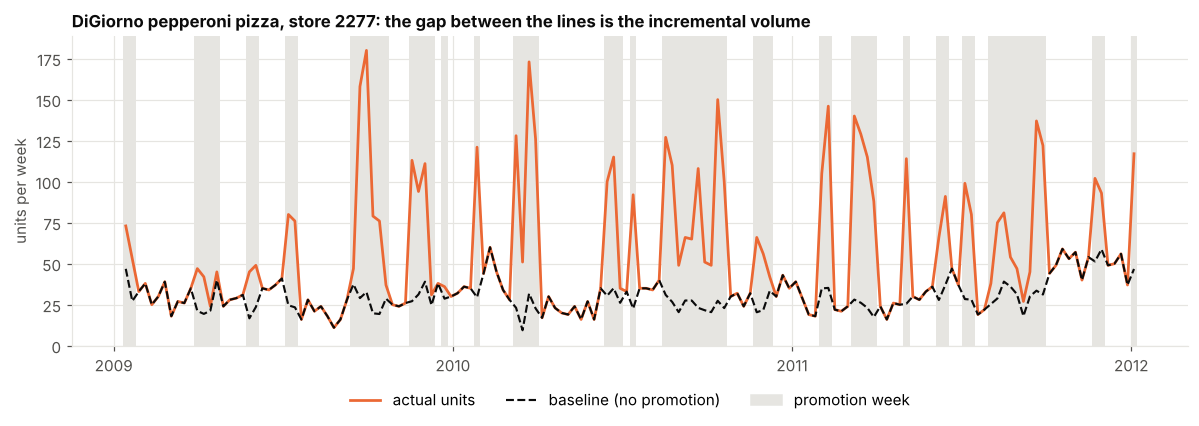

In [2]:
upc = 7192100339                                    # DiGiorno pepperoni pizza
store = df[df.upc == upc].groupby("store_id").units.sum().idxmax()  # its largest store
s = df[(df.upc == upc) & (df.store_id == store)].sort_values("week").copy()
m = models[upc]
s["baseline"] = s.units * np.exp(m.predict(s.assign(feature=0, display=0, log_price=s.log_base_price)) - m.predict(s))

fig, ax = plt.subplots(figsize=(11, 4))
for wk in s.loc[s.any_promo == 1, "week"]:
    ax.axvspan(wk - pd.Timedelta(days=3.5), wk + pd.Timedelta(days=3.5), color=GRID, lw=0)
ax.plot(s.week, s.units, color=CAT_COLOR["FROZEN PIZZA"], lw=1.8, label="actual units")
ax.plot(s.week, s.baseline, color=INK, lw=1.4, ls="--", label="baseline (no promotion)")
ax.fill_between([], [], color=GRID, label="promotion week")
ax.set_ylim(bottom=0)
ax.set_ylabel("units per week")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title(f"DiGiorno pepperoni pizza, store {store}: the gap between the lines is the incremental volume")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(FIG + "06_baseline_example.png", bbox_inches="tight")

Outside promotion weeks the two lines coincide. In promotion weeks the baseline stays at the normal level of that season while actual sales jump: the gap is what the promotion added. The baseline moves with the season and the holidays, which a simple average of non-promoted weeks would miss.

## 2. How much of the promoted volume is really incremental?

In [3]:
g = promos.groupby(["category", "mechanic"])
vol = pd.DataFrame({
    "promo_weeks": g.size(),
    "avg_discount_pct": 100 * g.discount_depth.mean(),
    "model_lift_x": g.units.sum() / g.baseline_units.sum(),
    "baseline_pct": 100 * g.baseline_units.sum() / g.units.sum(),
    "incr_from_price_pct": 100 * g.incr_from_price.sum() / g.units.sum(),
    "incr_from_support_pct": 100 * g.incr_from_support.sum() / g.units.sum(),
})
vol = vol.reindex(pd.MultiIndex.from_product([CAT_ORDER, MECHS])).rename(index=CAT_LABEL, level=0)
vol.round(1)

promo_weeks  avg_discount_pct  model_lift_x  baseline_pct  incr_from_price_pct  incr_from_support_pct
Frozen pizza TPR only                  9598              20.8           1.9          53.1                 46.9                    0.0
             Display                   5889              15.3           2.4          42.3                 26.4                   31.2
             Feature                   8100              22.5           2.6          38.3                 36.1                   25.6
             Feature + Display        10440              24.6           4.0          25.1                 28.4                   46.5
Cold cereal  TPR only                 18619              19.3           1.3          76.6                 23.4                    0.0
             Display                   5367              18.2           2.4          42.0                 23.6                   34.4
             Feature                   6664              21.0           2.6          37.8                 26.8                   35.4
             Feature + Display         9556              26.0           4.5          22.4                 18.3                   59.4
Mouthwash    TPR only                 21768              25.7           1.6          64.2                 35.8                    0.0
             Display                   8278              16.6           1.7          59.4                 22.0                   18.7
             Feature                   4369              27.8           2.6          39.0                 26.5                   34.5
             Feature + Display         1886              27.7           3.3          30.0                 19.8                   50.1
Pretzels     TPR only                 20748              20.5           1.2          86.1                 13.9                    0.0
             Display                  14757               6.7           1.4          71.2                  3.5                   25.3
             Feature                   1667              19.3           1.7          57.1                 12.2                   30.6
             Feature + Display         1494              21.4           2.4          40.9                 10.9                   48.2

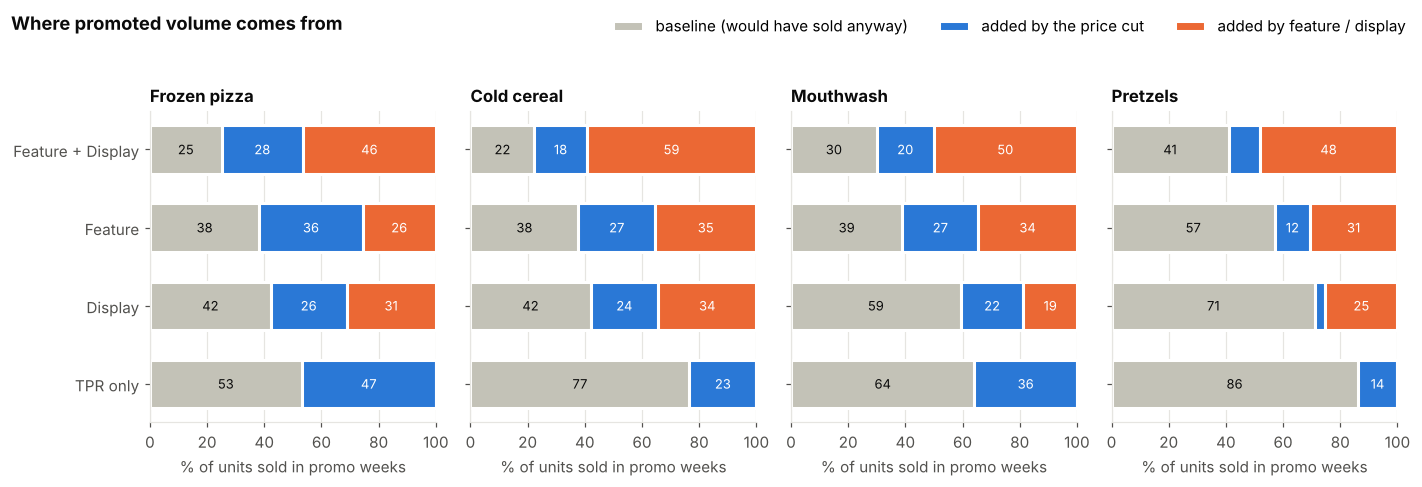

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2), sharey=True)
COL_BASE, COL_PRICE, COL_SUPPORT = "#c3c2b7", "#2a78d6", "#eb6834"
for ax, cat in zip(axes, CAT_ORDER):
    v = vol.loc[CAT_LABEL[cat]]
    y = np.arange(len(MECHS))
    left = np.zeros(len(MECHS))
    for col, color, lab in [("baseline_pct", COL_BASE, "baseline (would have sold anyway)"),
                            ("incr_from_price_pct", COL_PRICE, "added by the price cut"),
                            ("incr_from_support_pct", COL_SUPPORT, "added by feature / display")]:
        vals = v[col].values
        ax.barh(y, vals, left=left, color=color, height=0.62, edgecolor="white", linewidth=2, label=lab)
        for yi, (l, w) in enumerate(zip(left, vals)):
            if w >= 12:
                ax.text(l + w / 2, yi, f"{w:.0f}", ha="center", va="center", fontsize=8.5,
                        color=INK if color == COL_BASE else "white")
        left += vals
    ax.set_title(CAT_LABEL[cat])
    ax.set_xlim(0, 100)
    ax.set_yticks(y, MECHS)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("% of units sold in promo weeks")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=3, bbox_to_anchor=(0.995, 1.06))
fig.suptitle("Where promoted volume comes from", x=0.01, y=1.04, ha="left", fontweight="bold", color=INK, fontsize=12)
fig.tight_layout()
fig.savefig(FIG + "07_promo_volume_decomposition.png", bbox_inches="tight")

**Findings**
- **A price cut alone mostly discounts sales that would have happened anyway.** With TPR only, 53 % (pizza) to 86 % (pretzels) of the promoted units are baseline volume sold at a discount.
- **Feature + display turns most of the volume into extra sales**: 59 % (pretzels) to 78 % (cereal) of the promoted units are incremental.
- **Support, not price, does most of the work** when it is present: feature and display bring 41 % to 88 % of the incremental units, and more than half in 10 of the 12 supported combinations (the orange part is larger than the blue part). The raw ×3–×5 lift of notebook 01 is mainly a merchandising effect.

## 3. Does it pay?

Every promoted unit carries the discount, including baseline units. With gross margin *m* on the base price:

$$\text{incremental profit} = \text{incr. units} \times (m \cdot \text{base} - \text{discount}) - \text{baseline units} \times \text{discount}$$

The margin is not in the data, so the analysis gives, for each promotion, the **break-even margin** above which it adds profit, then the totals under three margin scenarios.

In [5]:
promos["breakeven_margin"] = breakeven_margin_of_promo(promos.units, promos.baseline_units,
                                                       promos.base_price, promos.price)
be = promos.groupby(["category", "mechanic"]).breakeven_margin.describe(percentiles=[.25, .5, .75])[["25%", "50%", "75%"]]
be = (100 * be).reindex(pd.MultiIndex.from_product([CAT_ORDER, MECHS])).rename(index=CAT_LABEL, level=0)
be.round(0)

25%    50%    75%
Frozen pizza TPR only           43.0   46.0   50.0
             Display             0.0   28.0   40.0
             Feature            29.0   37.0   44.0
             Feature + Display  26.0   35.0   41.0
Cold cereal  TPR only           61.0   83.0   87.0
             Display            11.0   34.0   44.0
             Feature            26.0   39.0   47.0
             Feature + Display  27.0   34.0   42.0
Mouthwash    TPR only           67.0   84.0   98.0
             Display             0.0   45.0   60.0
             Feature            39.0   49.0   56.0
             Feature + Display  33.0   42.0   47.0
Pretzels     TPR only           68.0  139.0  264.0
             Display             0.0    2.0   35.0
             Feature            33.0   44.0   55.0
             Feature + Display  28.0   36.0   41.0

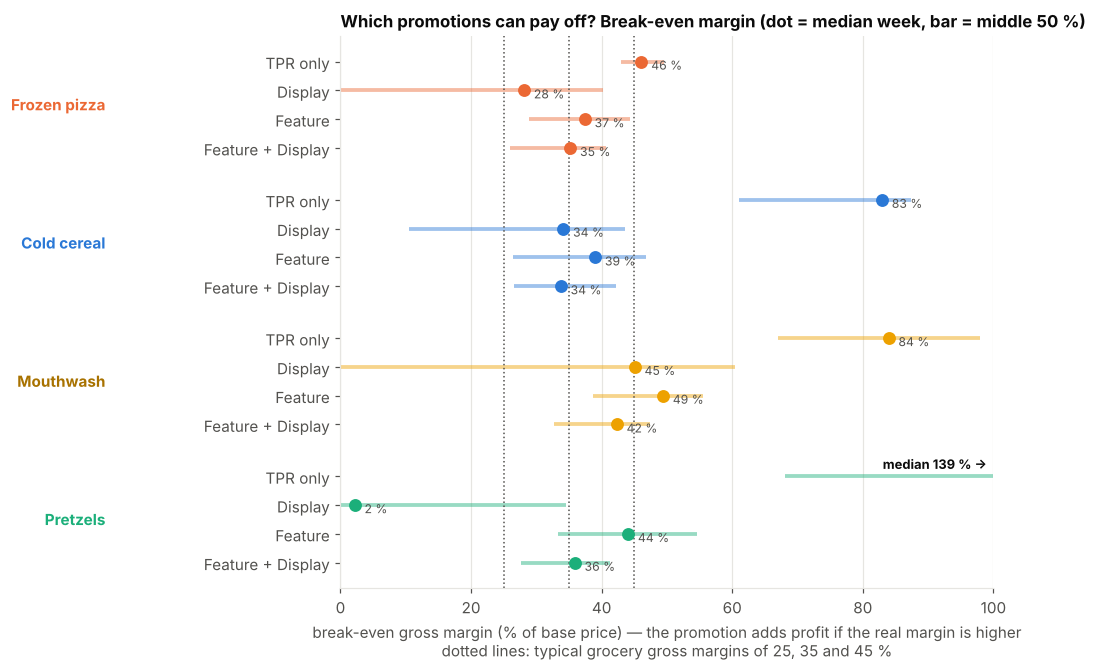

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.2))
rows = [(cat, mech) for cat in CAT_ORDER for mech in MECHS]
ypos, labels = [], []
y = 0
XMAX = 100
for cat in CAT_ORDER:
    for mech in MECHS:
        q = be.loc[(CAT_LABEL[cat], mech)]
        lo, med, hi = q["25%"], q["50%"], q["75%"]
        ax.hlines(y, min(lo, XMAX), min(hi, XMAX), color=CAT_COLOR[cat], lw=2.5, alpha=0.45)
        if med <= XMAX:
            ax.scatter(med, y, color=CAT_COLOR[cat], s=55, zorder=3)
            ax.text(med + 1.5, y + 0.28, f"{med:.0f} %", fontsize=8, color=INK2)
        else:
            ax.text(XMAX - 1, y - 0.42, f"median {med:.0f} % →", ha="right", va="center",
                    fontsize=8.5, color=INK, fontweight="bold")
        ypos.append(y); labels.append(mech)
        y += 1
    y += 0.8
for x in (25, 35, 45):
    ax.axvline(x, color=INK2, lw=1, ls=":")
ax.set_yticks(ypos, labels)
ax.invert_yaxis()
ax.set_xlim(0, XMAX)
ax.set_xlabel("break-even gross margin (% of base price) — the promotion adds profit if the real margin is higher\ndotted lines: typical grocery gross margins of 25, 35 and 45 %")
ax.grid(axis="y", visible=False)
# category labels in the left margin
y = 0
for cat in CAT_ORDER:
    ax.text(-0.36, y + 1.5, CAT_LABEL[cat], transform=ax.get_yaxis_transform(), ha="right", va="center",
            fontweight="bold", color=CAT_COLOR[cat] if cat != "ORAL HYGIENE PRODUCTS" else "#a87200")
    y += len(MECHS) + 0.8
ax.set_title("Which promotions can pay off? Break-even margin (dot = median week, bar = middle 50 %)")
fig.tight_layout()
fig.savefig(FIG + "08_breakeven_margin.png", bbox_inches="tight")

In [7]:
scen = []
for m in (0.25, 0.35, 0.45):
    e = promo_economics(promos, gross_margin=m).groupby(["category", "mechanic"])
    scen.append(pd.DataFrame({
        f"ROI at {int(100*m)} % margin": e.incremental_profit.sum() / e.trade_spend.sum(),
        f"profitable weeks at {int(100*m)} % (%)": 100 * e.incremental_profit.apply(lambda x: (x > 0).mean()),
    }))
roi = pd.concat(scen, axis=1).reindex(pd.MultiIndex.from_product([CAT_ORDER, MECHS])).rename(index=CAT_LABEL, level=0)
roi.round(2)

ROI at 25 % margin  profitable weeks at 25 % (%)  ROI at 35 % margin  profitable weeks at 35 % (%)  ROI at 45 % margin  profitable weeks at 45 % (%)
Frozen pizza TPR only                        -0.48                          0.00               -0.27                          0.96               -0.06                         39.08
             Display                         -0.31                         46.65               -0.03                         63.41                0.25                         88.64
             Feature                         -0.37                         18.57               -0.11                         39.52                0.14                         78.52
             Feature + Display               -0.30                         23.67               -0.02                         49.55                0.26                         96.42
Cold cereal  TPR only                        -0.71                          0.00               -0.60                          0.00               -0.48                          3.33
             Display                         -0.40                         31.88               -0.16                         54.16                0.08                         78.68
             Feature                         -0.44                         23.32               -0.21                         37.18                0.01                         69.43
             Feature + Display               -0.34                         22.23               -0.08                         53.63                0.18                         82.85
Mouthwash    TPR only                        -0.68                          0.00               -0.55                          0.00               -0.42                          0.00
             Display                         -0.52                         33.74               -0.33                         36.65               -0.14                         48.80
             Feature                         -0.49                          5.91               -0.29                         16.25               -0.09                         35.23
             Feature + Display               -0.43                          9.12               -0.20                         32.66                0.03                         63.26
Pretzels     TPR only                        -0.80                          0.00               -0.72                          0.00               -0.64                          0.00
             Display                          0.12                         65.07                0.57                         76.66                1.02                         89.36
             Feature                         -0.44                         13.32               -0.21                         28.85                0.01                         51.53
             Feature + Display               -0.30                         10.11               -0.02                         47.05                0.26                         85.81

**ROI** = incremental gross profit ÷ trade spend (discount × all promoted units). An ROI of −0.40 means that for every \$1 of discount given, the promotion lost \$0.40 of gross profit compared with not promoting.

**Findings**
- **TPR-only promotions never pay off at normal margins.** Their median break-even margin is 46 % (pizza) to 139 % (pretzels); at a 35 % margin, essentially no TPR week is profitable, and they lose \$0.27 to \$0.72 per \$1 of discount.
- **Supported promotions break even around a 35 % margin** in pizza, cereal and pretzels (median 28–44 %, pretzel display apart), so their profitability depends on who funds them and at what margin.
- **The best promotion in the data is a display on pretzels**: with only a 7 % average discount it adds 29 % of volume and pays off even at a 25 % margin (ROI +0.12, and +0.57 at 35 %).
- Mouthwash promotions are the hardest to justify: break-even margins of 42 % to 84 %.

## 4. Where the trade spend goes

In [8]:
e35 = promo_economics(promos, gross_margin=0.35)
spend = e35.groupby(["category", "mechanic"]).agg(trade_spend_usd=("trade_spend", "sum"),
                                                  incremental_profit_usd=("incremental_profit", "sum"),
                                                  spend_on_baseline_usd=("subsidised_spend", "sum"))
spend["share_of_category_spend_pct"] = 100 * spend.trade_spend_usd / spend.groupby(level=0).trade_spend_usd.transform("sum")
spend["spend_on_baseline_pct"] = 100 * spend.spend_on_baseline_usd / spend.trade_spend_usd
spend = spend.reindex(pd.MultiIndex.from_product([CAT_ORDER, MECHS])).rename(index=CAT_LABEL, level=0)
spend[["trade_spend_usd", "share_of_category_spend_pct", "spend_on_baseline_pct", "incremental_profit_usd"]].round(0)

trade_spend_usd  share_of_category_spend_pct  spend_on_baseline_pct  incremental_profit_usd
Frozen pizza TPR only                  155946.0                         14.0                   47.0                -42096.0
             Display                   151497.0                         14.0                   28.0                 -4439.0
             Feature                   252728.0                         23.0                   30.0                -28593.0
             Feature + Display         550855.0                         50.0                   21.0                -10542.0
Cold cereal  TPR only                  387273.0                         20.0                   72.0               -231727.0
             Display                   232475.0                         12.0                   33.0                -37986.0
             Feature                   397264.0                         20.0                   29.0                -83711.0
             Feature + Display         965588.0                         49.0                   19.0                -76174.0
Mouthwash    TPR only                  105580.0                         49.0                   61.0                -57850.0
             Display                    43444.0                         20.0                   47.0                -14411.0
             Feature                    40077.0                         19.0                   36.0                -11562.0
             Feature + Display          25663.0                         12.0                   27.0                 -5141.0
Pretzels     TPR only                  144194.0                         54.0                   83.0               -104250.0
             Display                    77762.0                         29.0                   56.0                 44573.0
             Feature                    16815.0                          6.0                   50.0                 -3596.0
             Feature + Display          29802.0                         11.0                   36.0                  -706.0

In [9]:
tpr = e35[e35.mechanic == "TPR only"]
print(f"TPR-only: {100 * tpr.trade_spend.sum() / e35.trade_spend.sum():.0f} % of all trade spend, "
      f"{100 * tpr.subsidised_spend.sum() / tpr.trade_spend.sum():.0f} % of it spent on units that would have sold anyway, "
      f"gross profit impact at a 35 % margin: ${tpr.incremental_profit.sum():,.0f}")
print(f"All promotions at a 35 % margin: ${e35.incremental_profit.sum():,.0f} on ${e35.trade_spend.sum():,.0f} of trade spend")

TPR-only: 22 % of all trade spend, 68 % of it spent on units that would have sold anyway, gross profit impact at a 35 % margin: $-435,923
All promotions at a 35 % margin: $-668,212 on $3,576,964 of trade spend


In pretzels and mouthwash, **TPR only absorbs about half of the trade spend (54 % and 49 %) while being the least effective mechanic**: 83 % and 61 % of its discount goes to units that would have sold anyway. Across all categories, at a 35 % margin, promotions as a whole lose gross profit; TPR only accounts for about two thirds of that loss with a fifth of the spend.

## 5. Recommendations

1. **Cut most TPR-only promotions**, starting with pretzels and mouthwash, and move the budget to display: it delivers more incremental volume per dollar of discount.
2. **Pretzels: favour display with a small discount.** It is the only promotion that pays off at a 25 % margin.
3. **Pizza and cereal: keep feature + display, but check the margin and who funds it.** They break even around 35 %; below that, a shallower discount with the same support would do better, because the support, not the price cut, drives most of the extra volume.
4. **Evaluate promotions on incremental profit, not on volume lift.** A ×3 lift can still lose money once the discount on baseline units is counted.

## Limits
- **Fixed costs of feature and display** (circular space, display fees) are not in the data; including them would lower every supported ROI.
- **Margins are assumed**, not observed: results are given as break-even margins and three scenarios.
- **Cannibalisation and store switching are not netted out**: part of the incremental volume may come from the brand's other products (strong for Snyder's, notebook 02) or from other stores. This is the retailer's or brand's view of a single product.
- The model assumes constant elasticity; the very deep discounts are few and less certain.